# Credit tables versus non-credit tables

Domain-specific continued pretraining assumes that credit tables share statistical regularities that non-credit tables do not. This notebook tests that premise separately for PD (credit default tables versus every binary non-credit table of the study) and LGD (loss-rate tables versus every regression non-credit table). Each table is described by the same properties of its features (size, feature types, missingness, skewness and tails of numeric features, single-feature association with the target) and of its target. Non-credit tables are the retention panel (never trained on) and the matched non-credit twins that E4 trains on (subsampled to their credit tables' rows and feature counts). Tables above 50,000 rows are subsampled to 50,000 rows for the property computation.

Four questions per task: where credit tables differ from non-credit tables; which properties they share (credit tables vary less among themselves than non-credit tables do); whether credit tables are closer to each other than to non-credit tables, separately in feature and in target properties; and what the targets look like.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import pandas as pd
from src.visualize import style, campaign as cp, domain as dv
from src.data import domain_comparison as dc
from src.visualize.figures import FigureSaver
style.apply()
sink = FigureSaver('general/03_domain_comparison')
report = cp.NotebookReport('Credit tables versus non-credit tables', sink=sink)
tables = {track: dc.load_groups(track) for track in ('pd', 'lgd')}
properties = {track: dc.property_table(tables[track], track) for track in ('pd', 'lgd')}

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


# Part A: PD tables versus non-credit binary tables

## A1. Properties of every table

One row per table.

In [2]:
report.table('PD table properties', properties['pd'])
report.add('A1. Properties of every table', 'Credit and non-credit binary tables described by the same properties.')

,dataset_id,group,rows,log10_rows,features,categorical_share,missing_share,median_abs_skew,heavy_tail_share,integer_share,max_abs_spearman,top5_abs_spearman,positive_rate
0,0001.gmsc,credit,150000,5.176091,10,0.000000,0.022416,24.532112,0.700000,0.800000,0.336549,0.246682,0.065900
1,0002.taiwan_creditcard,credit,30000,4.477121,23,0.000000,0.000000,2.663861,0.478261,1.000000,0.292213,0.209436,0.221200
2,0003.vehicle_loan,credit,233154,5.367643,33,0.090909,0.000981,6.384784,0.766667,0.966667,0.101121,0.074963,0.217720
3,0004.lendingclub,credit,9578,3.981275,13,0.076923,0.000000,1.034135,0.333333,0.500000,0.158119,0.134338,0.160054
4,0005.myhom,credit,7000,3.845098,8,0.125000,0.004375,2.308565,0.428571,1.000000,0.129573,0.070044,0.400000
5,0006.hackerearth,credit,532428,5.726261,36,0.250000,0.067200,1.792392,0.481481,0.666667,0.230156,0.139457,0.235620
6,0007.cobranded,credit,80000,4.903090,47,0.000000,0.188348,3.359099,0.617021,0.723404,0.418156,0.357822,0.247020
7,0008.german,credit,999,2.999565,20,0.650000,0.000000,1.094331,0.000000,1.000000,0.204931,0.104713,0.300300
8,PropPD1,credit,100000,5.000000,16,0.000000,0.060806,2.477289,0.500000,0.875000,0.107507,0.082062,0.227800
9,0010.thomas,credit,1225,3.088136,14,0.142857,0.000000,2.340682,0.416667,1.000000,0.191067,0.106438,0.263673


## A2. Where PD tables differ

Per property: credit and non-credit medians, Cliff's delta (from -1 to 1; an absolute value of 0.47 or more is a large difference) and the Mann-Whitney p-value, ordered by the size of the difference.

,property,credit_median,noncredit_median,cliffs_delta,mann_whitney_p
0,missing_share,0.008117,0.000000,0.457516,0.002959
1,log10_rows,4.903090,4.018414,0.307190,0.074731
2,max_abs_spearman,0.204931,0.295460,-0.269896,0.121489
3,positive_rate,0.221200,0.283917,-0.186275,0.281549
4,categorical_share,0.125000,0.153409,-0.174837,0.299127
5,top5_abs_spearman,0.121922,0.194378,-0.155709,0.373911
6,median_abs_skew,2.308565,1.519612,0.131488,0.453676
7,integer_share,0.777778,0.666667,0.122837,0.476749
8,features,20.000000,18.000000,0.071895,0.681334
9,heavy_tail_share,0.416667,0.379167,0.015571,0.935856


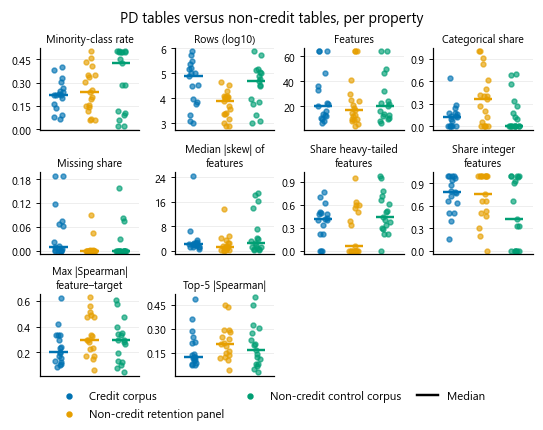

PD. Every PD credit table, binary non-credit retention table and matched non-credit control table (the E4 twins, subsampled to the shape of their credit tables), per property (panels). Points are tables with horizontal jitter; bars mark group medians. Tables above 50,000 rows are subsampled to 50,000 rows for the property computation.

In [3]:
report.table('PD: credit versus non-credit', dc.group_differences(properties['pd'], 'pd'))
cp.show(sink, [cp.Page(name='properties', figure=dv.property_figure(properties['pd'], 'pd'), caption='Every PD credit table, binary non-credit retention table and matched non-credit control table (the E4 twins, subsampled to the shape of their credit tables), per property (panels). Points are tables with horizontal jitter; bars mark group medians. Tables above 50,000 rows are subsampled to 50,000 rows for the property computation.')], track='pd')
report.add('A2. Where PD tables differ', 'Descriptive differences between the two table populations.')

## A3. What PD tables share

Interquartile range of each property among credit tables and among non-credit tables. A ratio well below 1 marks a property on which credit tables are alike, whatever its level.

In [4]:
report.table('PD: spread of each property', dc.dispersion(properties['pd'], 'pd'))
report.add('A3. What PD tables share', 'Properties ordered from most to least homogeneous among credit tables relative to non-credit tables.')

,property,credit_iqr,noncredit_iqr,credit_to_noncredit_ratio
0,positive_rate,0.103619,0.335045,0.309269
1,median_abs_skew,1.416058,3.465386,0.408629
2,categorical_share,0.181818,0.433824,0.419106
3,heavy_tail_share,0.268687,0.584375,0.459785
4,integer_share,0.330303,0.691667,0.477547
5,top5_abs_spearman,0.113296,0.160533,0.705751
6,max_abs_spearman,0.202593,0.278738,0.726821
7,log10_rows,1.355479,1.261903,1.074154
8,features,24.000000,19.750000,1.215190
9,missing_share,0.067200,0.000130,517.564540


## A4. Are PD tables closer to each other?

Mean distance between credit tables and between credit and non-credit tables in standardised property space, for all properties, feature properties only and target properties only; p-values from 5,000 permutations of the credit labels. Then the nearest table of every table.

In [5]:
report.table('PD: domain distance tests', pd.DataFrame([dc.domain_distance_test(properties['pd'], 'pd', subset=s) for s in ('all', 'table', 'target')]))
nearest = dc.nearest_neighbour_agreement(properties['pd'], 'pd')
report.table('PD: nearest table', nearest)
report.table('PD: share whose nearest table is from the same domain', nearest.groupby('domain').same_domain.mean().reset_index())
report.add('A4. Are PD tables closer to each other?', 'Distance tests and nearest neighbours; the projection of both tasks is in part C.')

,properties,credit_tables,noncredit_tables,mean_within_credit,mean_credit_to_noncredit,difference,permutation_p
0,all,17,36,4.036712,4.328411,0.291699,0.086383
1,table,17,36,3.935512,4.105884,0.170372,0.200560
2,target,17,36,0.735277,1.119386,0.384110,0.003599


,dataset_id,domain,nearest,nearest_domain,same_domain
0,0001.gmsc,credit,openml_46979,non-credit,False
1,0002.taiwan_creditcard,credit,0015.credit_risk_dataset,credit,True
2,0003.vehicle_loan,credit,PropPD1,credit,True
3,0004.lendingclub,credit,openml_46915,non-credit,False
4,0005.myhom,credit,openml_44130,non-credit,False
5,0006.hackerearth,credit,PropPD1,credit,True
6,0007.cobranded,credit,0012.home_credit,credit,True
7,0008.german,credit,openml_46940,non-credit,False
8,PropPD1,credit,openml_46922,non-credit,False
9,0010.thomas,credit,openml_46913,non-credit,False


,domain,same_domain
0,credit,0.529412
1,non-credit,0.722222


# Part B: LGD tables versus non-credit regression tables

## B1. Properties of every table

One row per table.

In [6]:
report.table('LGD table properties', properties['lgd'])
report.add('B1. Properties of every table', 'Credit and non-credit regression tables described by the same properties.')

,dataset_id,group,rows,log10_rows,features,categorical_share,missing_share,median_abs_skew,heavy_tail_share,integer_share,max_abs_spearman,top5_abs_spearman,bounded_unit_interval,share_at_min,share_at_max,target_skew,target_bimodality,unique_share
0,PropLGD1,credit,57932,4.762919,8,0.000000,0.038187,2.056752,0.375000,0.500000,0.320019,0.237109,True,0.218860,0.516860,-0.927010,0.916335,0.035600
1,PropLGD2,credit,4637,3.666237,52,0.442308,0.051048,7.271908,0.862069,0.413793,0.710449,0.548614,True,0.036230,0.037093,0.555772,0.528484,0.923873
2,PropLGD3,credit,2545,3.405688,2,0.000000,0.000000,1.884941,0.000000,0.500000,0.448277,0.296563,True,0.286051,0.056189,1.309706,0.827095,0.658153
3,PropLGD4,credit,762,2.881955,64,0.453125,0.110523,0.184871,0.028571,0.742857,0.298730,0.274236,True,0.104987,0.119423,0.828644,0.829442,0.574803
4,PropLGD5,credit,594,2.773786,64,0.281250,0.002262,0.617506,0.000000,0.130435,0.495573,0.314216,True,0.116162,0.159933,0.766211,0.885298,0.644781
5,0006.lgd_freddie,credit,16002,4.204174,20,0.400000,0.011727,3.449823,0.583333,0.916667,0.309821,0.277893,True,0.114173,0.080677,0.148691,0.537931,0.804774
6,0007.lgd_lendingclub,credit,5627,3.750277,17,0.294118,0.003293,0.994677,0.250000,0.666667,0.810966,0.243230,True,0.014750,0.003199,-0.464282,0.550145,0.980807
7,0008.SBA_loans_case,credit,686,2.836324,22,0.181818,0.003313,2.978826,0.611111,0.944444,0.390168,0.280790,True,0.001458,0.058309,-0.141185,0.500097,0.924198
8,openml_46954,retention,907,2.957607,6,0.000000,0.000000,0.711221,0.166667,0.333333,0.669017,0.368783,False,0.001103,0.001103,0.251356,0.289705,0.911797
9,openml_46917,retention,1030,3.012837,8,0.000000,0.000000,0.523481,0.125000,0.125000,0.596020,0.382619,False,0.000971,0.000971,0.416922,0.435569,0.910680


## B2. Where LGD tables differ

Per property: credit and non-credit medians, Cliff's delta (from -1 to 1; an absolute value of 0.47 or more is a large difference) and the Mann-Whitney p-value, ordered by the size of the difference.

,property,credit_median,noncredit_median,cliffs_delta,mann_whitney_p
0,share_at_max,0.069493,0.000870,0.95000,0.000008
1,bounded_unit_interval,1.000000,0.000000,0.95000,0.000002
2,share_at_min,0.109580,0.000706,0.91875,0.000205
3,missing_share,0.007520,0.000000,0.57500,0.008651
4,target_bimodality,0.688620,0.468098,0.50000,0.042843
5,categorical_share,0.287684,0.042949,0.32500,0.184222
6,unique_share,0.731464,0.392911,0.27500,0.280592
7,median_abs_skew,1.970846,1.041139,0.26250,0.303932
8,features,21.000000,10.500000,0.25000,0.318897
9,integer_share,0.583333,0.388889,0.24375,0.332996


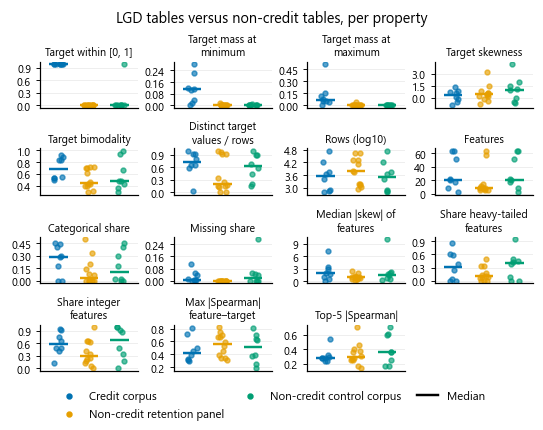

LGD. Every LGD credit table, regression non-credit retention table and matched non-credit control table (the E4 twins, subsampled to the shape of their credit tables), per property (panels). Points are tables with horizontal jitter; bars mark group medians. Tables above 50,000 rows are subsampled to 50,000 rows for the property computation.

In [7]:
report.table('LGD: credit versus non-credit', dc.group_differences(properties['lgd'], 'lgd'))
cp.show(sink, [cp.Page(name='properties', figure=dv.property_figure(properties['lgd'], 'lgd'), caption='Every LGD credit table, regression non-credit retention table and matched non-credit control table (the E4 twins, subsampled to the shape of their credit tables), per property (panels). Points are tables with horizontal jitter; bars mark group medians. Tables above 50,000 rows are subsampled to 50,000 rows for the property computation.')], track='lgd')
report.add('B2. Where LGD tables differ', 'Descriptive differences between the two table populations.')

## B3. What LGD tables share

Interquartile range of each property among credit tables and among non-credit tables. A ratio well below 1 marks a property on which credit tables are alike, whatever its level.

In [8]:
report.table('LGD: spread of each property', dc.dispersion(properties['lgd'], 'lgd'))
report.add('B3. What LGD tables share', 'Properties ordered from most to least homogeneous among credit tables relative to non-credit tables.')

,property,credit_iqr,noncredit_iqr,credit_to_noncredit_ratio
0,top5_abs_spearman,0.034492,0.165489,0.208424
1,unique_share,0.296668,0.752134,0.394435
2,integer_share,0.307861,0.544730,0.565163
3,max_abs_spearman,0.231823,0.319372,0.725872
4,target_skew,1.003779,1.192128,0.842006
5,log10_rows,0.993204,1.133757,0.876029
6,target_bimodality,0.307837,0.298756,1.030396
7,categorical_share,0.274213,0.223529,1.226744
8,heavy_tail_share,0.568849,0.332843,1.709061
9,features,40.250000,21.750000,1.850575


## B4. Are LGD tables closer to each other?

Mean distance between credit tables and between credit and non-credit tables in standardised property space, for all properties, feature properties only and target properties only; p-values from 5,000 permutations of the credit labels. Then the nearest table of every table.

In [9]:
report.table('LGD: domain distance tests', pd.DataFrame([dc.domain_distance_test(properties['lgd'], 'lgd', subset=s) for s in ('all', 'table', 'target')]))
nearest = dc.nearest_neighbour_agreement(properties['lgd'], 'lgd')
report.table('LGD: nearest table', nearest)
report.table('LGD: share whose nearest table is from the same domain', nearest.groupby('domain').same_domain.mean().reset_index())
report.add('B4. Are LGD tables closer to each other?', 'Distance tests and nearest neighbours; the projection of both tasks is in part C.')

,properties,credit_tables,noncredit_tables,mean_within_credit,mean_credit_to_noncredit,difference,permutation_p
0,all,8,20,5.381486,5.930988,0.549502,0.085983
1,table,8,20,4.071211,4.073802,0.002590,0.476705
2,target,8,20,3.183348,4.045348,0.862000,0.014197


,dataset_id,domain,nearest,nearest_domain,same_domain
0,PropLGD1,credit,PropLGD3,credit,True
1,PropLGD2,credit,0006.lgd_freddie,credit,True
2,PropLGD3,credit,PropLGD5,credit,True
3,PropLGD4,credit,PropLGD5,credit,True
4,PropLGD5,credit,PropLGD4,credit,True
5,0006.lgd_freddie,credit,0008.SBA_loans_case,credit,True
6,0007.lgd_lendingclub,credit,0008.SBA_loans_case,credit,True
7,0008.SBA_loans_case,credit,openml_42570,non-credit,False
8,openml_46954,non-credit,openml_46917,non-credit,True
9,openml_46917,non-credit,openml_46954,non-credit,True


,domain,same_domain
0,credit,0.875
1,non-credit,0.850


## B5. The target

Distribution of each table's target after per-table rescaling, and the share of rows exactly at the minimum and maximum target value.

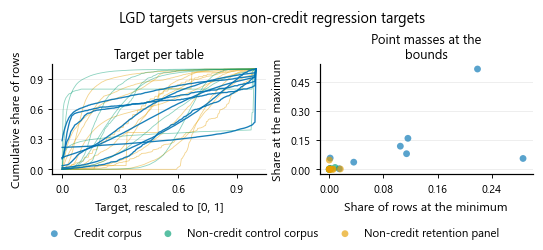

Left: empirical distribution function of each table target after per-table min-max rescaling. Right: share of rows exactly at the minimum and at the maximum target value. Colours mark credit LGD tables and non-credit regression tables.

In [10]:
cp.show(sink, [cp.Page(name='lgd_targets', figure=dv.target_figure(tables['lgd'], properties['lgd']), caption='Left: empirical distribution function of each table target after per-table min-max rescaling. Right: share of rows exactly at the minimum and at the maximum target value. Colours mark credit LGD tables and non-credit regression tables.')])
report.add('B5. The target', 'Target shape per table.')

# Part C: both tasks in one projection

## C1. Projection of table properties

First two principal components of the standardised feature and target properties, separately for PD with the binary non-credit tables and for LGD with the regression non-credit tables. Distances in the full property space are tested in A4 and B4; two components show only part of that variance.

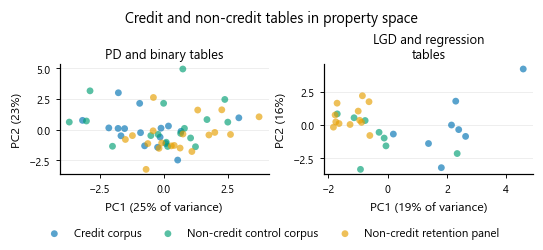

First two principal components of the standardised feature and target properties of every table, for PD with the binary non-credit tables (left) and LGD with the regression non-credit tables (right). Each point is one table: credit corpus, matched non-credit control corpus (E4) and non-credit retention panel. Axis labels give the share of property variance per component.

In [11]:
embeddings = {track: dc.embedding(properties[track], track) for track in ('pd', 'lgd')}
cp.show(sink, [cp.Page(name='embedding', figure=dv.embedding_figure(embeddings, 'Credit and non-credit tables in property space'), caption='First two principal components of the standardised feature and target properties of every table, for PD with the binary non-credit tables (left) and LGD with the regression non-credit tables (right). Each point is one table: credit corpus, matched non-credit control corpus (E4) and non-credit retention panel. Axis labels give the share of property variance per component.')])
report.add('C1. Projection of table properties', 'Two components; the distance tests in A4 and B4 use all properties.')

## Summary

Every displayed table and figure, in section order.

In [12]:
print(report.summary(sink))

Credit tables versus non-credit tables

A1. Properties of every table
Credit and non-credit binary tables described by the same properties.

Table: PD table properties
CSV (first column: row index)
row,dataset_id,group,rows,log10_rows,features,categorical_share,missing_share,median_abs_skew,heavy_tail_share,integer_share,max_abs_spearman,top5_abs_spearman,positive_rate
0,0001.gmsc,credit,150000,5.1760913,10,0,0.022416,24.532112,0.7,0.8,0.33654882,0.2466822,0.0659
1,0002.taiwan_creditcard,credit,30000,4.4771213,23,0,0,2.663861,0.47826087,1,0.29221322,0.2094358,0.2212
2,0003.vehicle_loan,credit,233154,5.3676429,33,0.090909091,0.00098121212,6.3847838,0.76666667,0.96666667,0.1011205,0.074962646,0.21772
3,0004.lendingclub,credit,9578,3.9812748,13,0.076923077,0,1.0341353,0.33333333,0.5,0.15811915,0.134338,0.16005429
4,0005.myhom,credit,7000,3.845098,8,0.125,0.004375,2.3085652,0.42857143,1,0.12957273,0.070044377,0.4
5,0006.hackerearth,credit,532428,5.7262609,36,0.25,0.0672,1.7923922,0.4814814